# Credit card default scorecard: a walkthrough

**Question.** Of 30,000 credit card holders at a bank in Taiwan (April to September 2005), who will miss next month's payment, and where should a lender draw the line between approving and declining?

**Approach.** A points scorecard built the way banks build them (weight of evidence, logistic regression, points), tested against a gradient-boosting model and a naive rule, checked for calibration and fairness, then priced: the cut-off that earns most depends on the card's yield, the loss on a default, and the cost of money, which here is the State Bank of Pakistan's policy rate.

**Short answer.** On 6,000 hold-out accounts the scorecard has an AUC of 0.768 against 0.706 for a rule that only reads last month's status and 0.792 for gradient boosting. Under the stated assumptions an account is worth approving while its probability of default is under 10.8%, which approves 28% of the hold-out accounts (section 8).

The cardholders are from Taiwan, not Pakistan, and "default" means a missed payment, not a write-off. The yield, running cost and loss in the economics are assumptions. This notebook refits the scorecard from the raw file in a few seconds and checks it against the committed results; everything else it reads from `data/processed`. Nothing here is lending advice.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
# the same functions the pipeline uses
from creditrisk import binning, build, config, economics, models, scorecard, validation  # noqa: E402

P = ROOT / "data" / "processed"
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

summary = json.loads((P / "summary.json").read_text())
accounts, quality = build.clean(build.load_raw())
accounts = build.add_features(accounts)
print(f"{len(accounts):,} accounts, {accounts['default'].mean():.1%} defaulted the next month; {len(build.BEHAVIOUR)} behaviour columns")

30,000 accounts, 22.1% defaulted the next month; 39 behaviour columns


## 1. What is in the file and what was cleaned

The file has no missing values. The documentation does not explain a few codes (education 0, 5 and 6, marital status 0), which are put with "others"; some identical accounts are mostly dormant cards. Nothing is dropped.

In [2]:
# What cleaning found (the full record is data/processed/data_quality.json). Nothing was dropped.
pd.Series({k: v for k, v in quality.items() if not isinstance(v, dict)})

rows                            30,000.000
default_rate                         0.221
defaults                         6,636.000
education_recoded                  345.000
marriage_recoded                    54.000
rows_in_repeated_groups            108.000
extra_copies                        56.000
repeated_rows_dormant               97.000
accounts_with_a_negative_bill    1,930.000
over_limit_in_september          2,115.000
no_bills_in_six_months             866.000
no_payments_in_six_months        1,432.000
dtype: float64

In [3]:
# A repayment status of 1 ("one month late") hardly appears before September: the older months seem to be coded on another basis.
pd.DataFrame({"late (status 1 or more)": quality["late_share_by_month"], "status exactly 1": quality["status_one_by_month"],
              "status exactly 2": quality["status_two_by_month"]}).T[list(config.MONTHS)]

,sep,aug,jul,jun,may,apr
late (status 1 or more),0.227,0.148,0.140,0.117,0.099,0.103
status exactly 1,"3,688.000",28.000,4.000,2.000,0.000,0.000
status exactly 2,"2,667.000","3,927.000","3,819.000","3,159.000","2,626.000","2,766.000"


## 2. Who defaults

Last month's repayment status is the strongest single signal, and the credit limit (which the bank itself chose) is a strong one too.

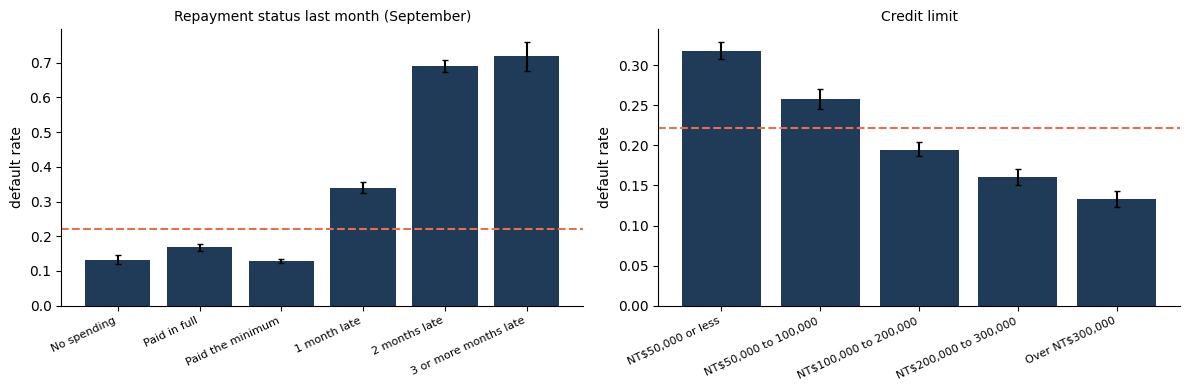

In [4]:
seg = pd.read_csv(P / "segments.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, variable in zip(axes, ["Repayment status last month (September)", "Credit limit"], strict=True):
    s = seg[seg["variable"] == variable].sort_values("position")
    ax.bar(range(len(s)), s["default_rate"], color="#1F3B57", yerr=[s["default_rate"] - s["ci_low"], s["ci_high"] - s["default_rate"]], capsize=2)
    ax.axhline(summary["data"]["default_rate"], color="#E76F51", ls="--")
    ax.set_xticks(range(len(s)), s["group"], rotation=25, ha="right", fontsize=8)
    ax.set_title(variable, fontsize=10)
    ax.set_ylabel("default rate")
plt.tight_layout()
plt.show()

## 3. The split

Everything (bins, features, settings, cut-off) is chosen on the development accounts. The hold-out is used once, to report.

In [5]:
# One split, made once: 80% to build everything on, 20% kept aside. Identical accounts never straddle it.
development, holdout = models.holdout_split(accounts)
dev, hold = accounts.iloc[development].reset_index(drop=True), accounts.iloc[holdout].reset_index(drop=True)
y_dev, y_hold = dev["default"].to_numpy(), hold["default"].to_numpy()
shared = set(dev["group"]) & set(hold["group"])
print(f"{len(dev):,} development and {len(hold):,} hold-out accounts; default rates {y_dev.mean():.2%} and {y_hold.mean():.2%}; "
      f"identical accounts on both sides: {len(shared)}")

24,000 development and 6,000 hold-out accounts; default rates 22.12% and 22.12%; identical accounts on both sides: 0


## 4. Weight of evidence and information value

A feature is cut into bins; each bin gets a weight of evidence, ln(share of bad accounts / share of good accounts), positive where the bin is riskier than average. The information value sums how far the bins pull good and bad apart. The cell computes both by hand for last month's status and checks them against the library.

In [6]:
# Weight of evidence by hand, for last month's repayment status.
b = binning.fit_binning(dev["status_sep"], y_dev, "status_sep", "numeric")
t = b.table
share_bad = (t["bad"] + 0.5) / (t["bad"].sum() + 0.5 * len(t))      # half an account is added to every bin so that no bin has an infinite weight
share_good = (t["good"] + 0.5) / (t["good"].sum() + 0.5 * len(t))
by_hand = np.log(share_bad / share_good)
assert np.allclose(by_hand, t["woe"]) and np.isclose(((share_bad - share_good) * by_hand).sum(), b.iv)
print(f"information value {b.iv:.3f}: above 0.3 is strong")
t[["label", "n", "bad_rate", "woe", "iv"]]

information value 0.882: above 0.3 is strong


,label,n,bad_rate,woe,iv
0,-2,2205,0.133,-0.616,0.029
1,-1,4539,0.166,-0.355,0.021
2,0,11788,0.127,-0.667,0.179
3,1,2946,0.343,0.608,0.053
4,2 or more,2522,0.695,2.080,0.601


## 5. The scorecard

The full recipe is in `creditrisk/scorecard.py`: bin every candidate, drop features with little information, thin out correlated ones, fit a logistic regression and drop any feature that is not significant or has the wrong sign, then turn the regression into whole points. The cell below refits it on the development accounts and checks that it reproduces the committed hold-out result.

In [7]:
# Fit the scorecard on the development accounts and compare with the committed hold-out result.
card = scorecard.Scorecard().fit(dev, y_dev)
p_hold = card.predict_proba(hold)
stored = summary["metrics"]["scorecard"]
print(f"hold-out AUC {validation.auc(y_hold, p_hold):.4f} here, {stored['auc']:.4f} in the results; KS {validation.ks(y_hold, p_hold):.4f} here, {stored['ks']:.4f} in the results")
assert abs(validation.auc(y_hold, p_hold) - stored["auc"]) < 1e-3 and abs(validation.ks(y_hold, p_hold) - stored["ks"]) < 2e-3
card.screening_[["feature", "iv", "decision", "reason"]].round(3)

hold-out AUC 0.7681 here, 0.7681 in the results; KS 0.4023 here, 0.4023 in the results


,feature,iv,decision,reason
0,status_sep,0.882,kept,
1,n_delinquent,0.837,dropped,"correlated with status_sep (r = 0.75), which h..."
2,n_delinquent_recent,0.831,dropped,"correlated with status_sep (r = 0.84), which h..."
3,months_since_delinquent,0.799,dropped,"correlated with status_sep (r = 0.85), which h..."
4,worst_status,0.738,dropped,"correlated with status_sep (r = 0.68), which h..."
5,status_aug,0.560,dropped,"correlated with status_sep (r = 0.67), which h..."
6,status_jul,0.410,kept,
7,status_jun,0.345,dropped,"correlated with status_jul (r = 0.62), which h..."
8,status_may,0.325,kept,
9,status_apr,0.282,dropped,"correlated with status_may (r = 0.65), which h..."


In [8]:
print(f"{len(card.features_)} features, {int(len(card.points_table()))} bins; the score is the sum of the points (higher is safer)")
card.points_range().rename("points between best and worst bin").to_frame().T

8 features, 37 bins; the score is the sum of the points (higher is safer)


,status_sep,paid_total,status_may,status_jul,utilisation_avg,limit,paid_sep,pay_ratio_sep
points between best and worst bin,121,37,31,28,22,20,14,9


In [9]:
pts = card.points_table()
top = card.points_range().index[:3]
pts[pts["feature"].isin(top)].rename(columns={"default_rate": "default rate"}).round(3)

,feature,bin,accounts,default rate,woe,points
0,status_sep,-2,2205,0.133,-0.616,89
1,status_sep,-1,4539,0.166,-0.355,78
2,status_sep,0,11788,0.127,-0.667,92
3,status_sep,1,2946,0.343,0.608,36
4,status_sep,2 or more,2522,0.695,2.080,-29
9,status_may,-2,3641,0.198,-0.140,65
10,status_may,-1,4418,0.158,-0.411,69
11,status_may,0 to 1,13561,0.190,-0.190,66
12,status_may,2 or more,2380,0.550,1.457,38
16,paid_total,"7,100 or less",6426,0.308,0.449,51


## 6. From points to probability

The score is 600 at odds of 20 good accounts to 1 bad one, and every 40 points double the odds. The probability of default is read straight from the whole-number score, so the card and the probability always agree.

In [10]:
s = card.scaling
odds = lambda score: (1 - s.probability(score)) / s.probability(score)  # noqa: E731
print(f"{s.base_score} points <-> probability of default {s.probability(s.base_score):.2%} (odds {s.base_odds}:1)")
print(f"{s.base_score + s.pdo} points: odds {odds(s.base_score + s.pdo):.1f}:1, exactly double; {s.base_score - s.pdo} points: odds {odds(s.base_score - s.pdo):.1f}:1")
card.reason_codes(hold.head(2), k=3)  # the reasons an account lost points, worst first

600 points <-> probability of default 4.76% (odds 20:1)
640 points: odds 40.0:1, exactly double; 560 points: odds 10.0:1


[[('paid_total', '7,101 to 14,300', 31),
  ('limit', '70,001 to 140,000', 11),
  ('paid_sep', '1 to 3,900', 7)],
 [('paid_total', '7,101 to 14,300', 31),
  ('utilisation_avg', 'over 0.503 up to 0.802', 15),
  ('limit', '30,001 to 70,000', 14)]]

## 7. How good is it?

Against a naive rule and a gradient-boosting model, on the hold-out accounts. AUC is the chance that a random defaulter scores riskier than a random payer; KS is the largest gap between the two groups' cumulative score distributions. The second table looks only at accounts that were not late last month, where a rule that reads last month's status has nothing to go on.

In [11]:
metrics = pd.read_csv(P / "holdout_metrics.csv").set_index("model")
metrics.loc[["naive", "scorecard", "challenger"], ["auc", "auc_low", "auc_high", "ks", "brier", "calibration_slope", "capture_top_decile"]]

,auc,auc_low,auc_high,ks,brier,calibration_slope,capture_top_decile
model,,,,,,,
naive,0.706,0.688,0.723,0.356,0.143,0.982,0.317
scorecard,0.768,0.752,0.783,0.402,0.137,0.997,0.312
challenger,0.792,0.777,0.806,0.443,0.133,1.010,0.317


In [12]:
# The hard half: accounts that were not late last month, where a rule that only reads last month's status has nothing to go on.
pd.read_csv(P / "subset_metrics.csv")[["subset", "model", "accounts", "default_rate", "auc", "ks", "capture_top_decile"]]

,subset,model,accounts,default_rate,auc,ks,capture_top_decile
0,Not late in September,naive,4650,0.142,0.532,0.066,0.135
1,Not late in September,scorecard,4650,0.142,0.664,0.245,0.205
2,Not late in September,challenger,4650,0.142,0.706,0.291,0.255
3,Late in September,naive,1350,0.494,0.687,0.369,0.142
4,Late in September,scorecard,1350,0.494,0.738,0.373,0.160
5,Late in September,challenger,1350,0.494,0.751,0.374,0.174


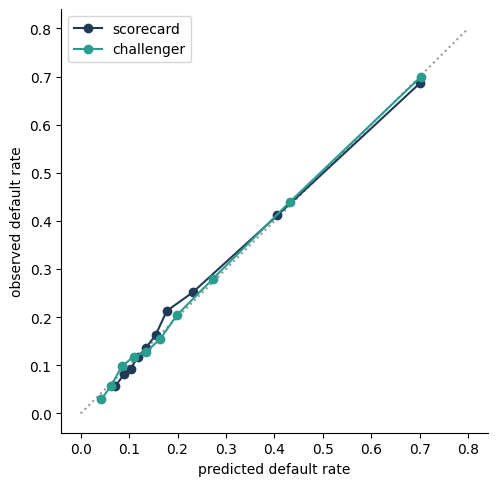

In [13]:
cal = pd.read_csv(P / "calibration.csv")
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 0.8], [0, 0.8], color="#999", ls=":")
for model, colour in [("scorecard", "#1F3B57"), ("challenger", "#2A9D8F")]:
    c = cal[cal["model"] == model]
    ax.plot(c["predicted"], c["observed"], "o-", color=colour, label=model)
ax.set_xlabel("predicted default rate")
ax.set_ylabel("observed default rate")
ax.legend()
plt.show()

## 8. Where to draw the line

Over one billing month an approved account that pays earns a margin on its balance, and one that defaults loses a share of it. Approving pays while the probability of default is under margin / (margin + loss). The margin comes from the card's APR (MCB publishes 3.67% a month, up to 44% a year), the share of balances that revolve (measured in this file), the cost of money (the policy rate) and a running cost; the loss is an assumption.

In [14]:
# The economics: an account that pays earns a margin on its balance, one that defaults loses a share of it.
e = summary["economics"]
econ = economics.Economics(apr=e["apr"], revolve_share=economics.revolve_share(dev), funding=e["funding"], opex=e["opex"], loss=e["loss"])
assert abs(econ.break_even - e["break_even_pd"]) < 1e-9
print(f"yield {econ.yield_:.1%} - funding {econ.funding:.2%} - running cost {econ.opex:.0%} = {econ.margin * 12:.1%} a year = {econ.margin:.3%} a month")
print(f"break-even probability of default = margin / (margin + loss) = {econ.break_even:.2%}; score {int(np.ceil(card.scaling.score(econ.break_even)))}")

yield 38.8% - funding 12.00% - running cost 5% = 21.8% a year = 1.819% a month
break-even probability of default = margin / (margin + loss) = 10.81%; score 549


approved 28.4% of hold-out accounts; 7.6% of them defaulted; profit 42 NT$ per account a month


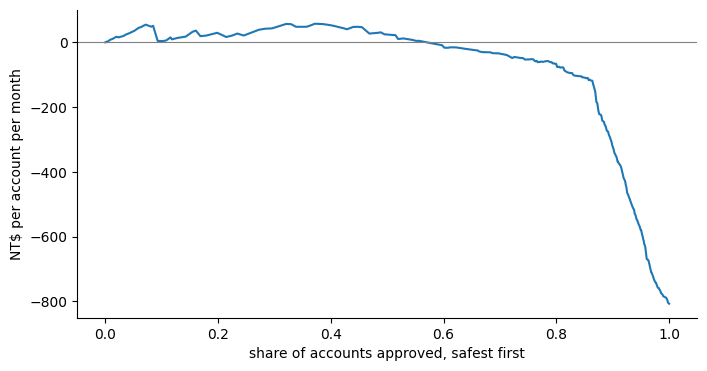

In [15]:
table = economics.threshold_table(y_hold, p_hold, economics.exposure(hold))
result = economics.profit_at(table, econ, econ.break_even)
row = pd.read_csv(P / "cutoffs.csv").query("model == 'scorecard' and rule == 'break-even probability'").iloc[0]
assert abs(result["approved_share"] - row["approved_share"]) < 1e-9
assert abs(result["realised_profit"] / len(hold) - row["profit_per_account"]) < 1e-6
print(f"approved {result['approved_share']:.1%} of hold-out accounts; {result['default_rate_approved']:.1%} of them defaulted; "
      f"profit {result['realised_profit'] / len(hold):,.0f} NT$ per account a month")
curve = economics.profit_curve(table, econ)
ax = (curve.set_index("approved_share")["realised_profit"] / len(hold)).plot(figsize=(8, 4))
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("share of accounts approved, safest first")
ax.set_ylabel("NT$ per account per month")
plt.show()

## 9. What the policy rate does to the cut-off

When the State Bank raised its rate from 7.25% to 22%, the margin on a card balance shrank and the break-even probability fell: a lender that kept its 2021 cut-off through 2023 would have approved accounts that lost money.

In [16]:
pd.read_csv(P / "scenarios.csv")[["date", "policy_rate", "break_even_pd", "approved_share", "profit_per_account", "profit_per_account_first_cutoff_kept"]]

,date,policy_rate,break_even_pd,approved_share,profit_per_account,profit_per_account_first_cutoff_kept
0,2021-10-01,0.072,0.129,0.423,155.997,155.997
1,2022-07-08,0.150,0.095,0.179,-10.535,-27.642
2,2023-06-27,0.220,0.062,0.010,3.619,-193.509
3,2024-12-17,0.130,0.104,0.245,7.077,19.749
4,2025-12-16,0.105,0.115,0.330,84.916,78.987
5,2026-10-27,0.120,0.108,0.284,42.303,43.444


## 10. Fairness

Sex, age, education and marital status are not inputs. The audit shows what the decisions do to each group at the cut-off. The disparate-impact ratio flags a group approved at under four-fifths of the best group's rate; it is a screening rule, not a legal test in Pakistan.

In [17]:
f = pd.read_csv(P / "fairness_groups.csv").query("model == 'scorecard'")
f[["attribute", "group", "accounts", "default_rate", "mean_probability", "approval_rate", "disparate_impact", "flagged"]].round(3)

,attribute,group,accounts,default_rate,mean_probability,approval_rate,disparate_impact,flagged
0,sex,Female,3645,0.209,0.208,0.302,1.000,False
1,sex,Male,2355,0.241,0.236,0.257,0.851,False
2,age_band,21-29,1936,0.231,0.236,0.227,0.662,True
3,age_band,30-39,2222,0.201,0.202,0.342,1.000,False
4,age_band,40-49,1283,0.227,0.215,0.294,0.858,False
5,age_band,50 and over,559,0.254,0.235,0.231,0.674,True
6,education,Graduate school,2082,0.189,0.191,0.371,1.000,False
7,education,High school,991,0.256,0.259,0.179,0.482,True
8,education,Other or unknown,93,0.054,0.164,0.419,NaN,False
9,education,University,2834,0.238,0.227,0.253,0.683,True


## 11. Limits

- **Not Pakistani data.** The accounts are Taiwanese from 2005, a crisis-era book where 22% missed a payment in one month. What carries over to Pakistan is the method and the link between the policy rate and the cut-off.
- **Default is a missed payment**, not a charge-off, so the loss on a default is an assumption.
- **One cohort.** There is no later period to test the scorecard's stability against.
- **Selection.** Only accounts the bank had approved are here.
- **The assumptions drive the cut-off.** Only the card APR and the policy rate are sourced; see the sensitivity table in the dashboard.